In [1]:
import sys
import os
sys.path.append(os.path.abspath('../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import weibull_min
from lifelines import WeibullFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

In [2]:
# Load your data
dataset = pd.read_csv("data/cleaning/data_treated_clean.csv")

# Remove duplicates (same as in other notebooks)
mask = dataset.duplicated(subset='PERSON_ID', keep=False)
to_remove = (
    dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)
survival_dataset = dataset.drop(to_remove)
survival_dataset = survival_dataset.drop('Unnamed: 0', axis=1, errors='ignore')

# Extract survival data
survival_times = survival_dataset['Survival days'].values
events = survival_dataset['Regional LN recurrence'].values

print("=== DATA SUMMARY ===")
print(f"Total observations: {len(survival_times)}")
print(f"Events (uncensored): {events.sum()} ({events.mean()*100:.1f}%)")
print(f"Censored: {(1-events).sum()} ({(1-events).mean()*100:.1f}%)")
print(f"Time range: {survival_times.min()} to {survival_times.max()} days")
print(f"Median time: {np.median(survival_times):.1f} days")

=== DATA SUMMARY ===
Total observations: 2970
Events (uncensored): 33.0 (1.1%)
Censored: 2937.0 (98.9%)
Time range: 25.0 to 7492.0 days
Median time: 1346.0 days


# Goodness-of-Fit Analysis: Weibull Distribution

## Overview
We will conduct multiple tests to assess if the survival data follows a Weibull distribution:
1. **Visual Assessment**: Q-Q plots and overlays
2. **Kolmogorov-Smirnov Test**: Statistical test for distribution fit
3. **Anderson-Darling Test**: More sensitive to tail differences
4. **Chi-Square Test**: Compare observed vs expected frequencies
5. **AIC/BIC Comparison**: Model comparison metrics
6. **Cox-Snell Residuals**: Diagnostic plot for parametric fit

In [3]:
# 1. Fit Weibull distribution to the data using lifelines
print("=== FITTING WEIBULL DISTRIBUTION ===\n")

# Fit Weibull using lifelines (handles censoring properly)
weibull_fitter = WeibullFitter()
weibull_fitter.fit(survival_times, events, label='Weibull Fit')

# Extract Weibull parameters
lambda_param = weibull_fitter.lambda_
rho_param = weibull_fitter.rho_

print(f"Weibull Parameters:")
print(f"  λ (lambda/scale): {lambda_param:.4f}")
print(f"  ρ (rho/shape):    {rho_param:.4f}")
print(f"\nWeibull Interpretation:")
if rho_param < 1:
    print(f"  ρ < 1: Hazard rate DECREASES over time (early failures)")
elif rho_param == 1:
    print(f"  ρ = 1: Constant hazard rate (exponential distribution)")
else:
    print(f"  ρ > 1: Hazard rate INCREASES over time (wear-out failures)")

# Also fit Kaplan-Meier for comparison
km_fitter = KaplanMeierFitter()
km_fitter.fit(survival_times, events, label='Kaplan-Meier')

=== FITTING WEIBULL DISTRIBUTION ===

Weibull Parameters:
  λ (lambda/scale): 31845.8758
  ρ (rho/shape):    1.4818

Weibull Interpretation:
  ρ > 1: Hazard rate INCREASES over time (wear-out failures)


<lifelines.KaplanMeierFitter:"Kaplan-Meier", fitted with 2970 total observations, 2937 right-censored observations>


=== VISUAL COMPARISON ===


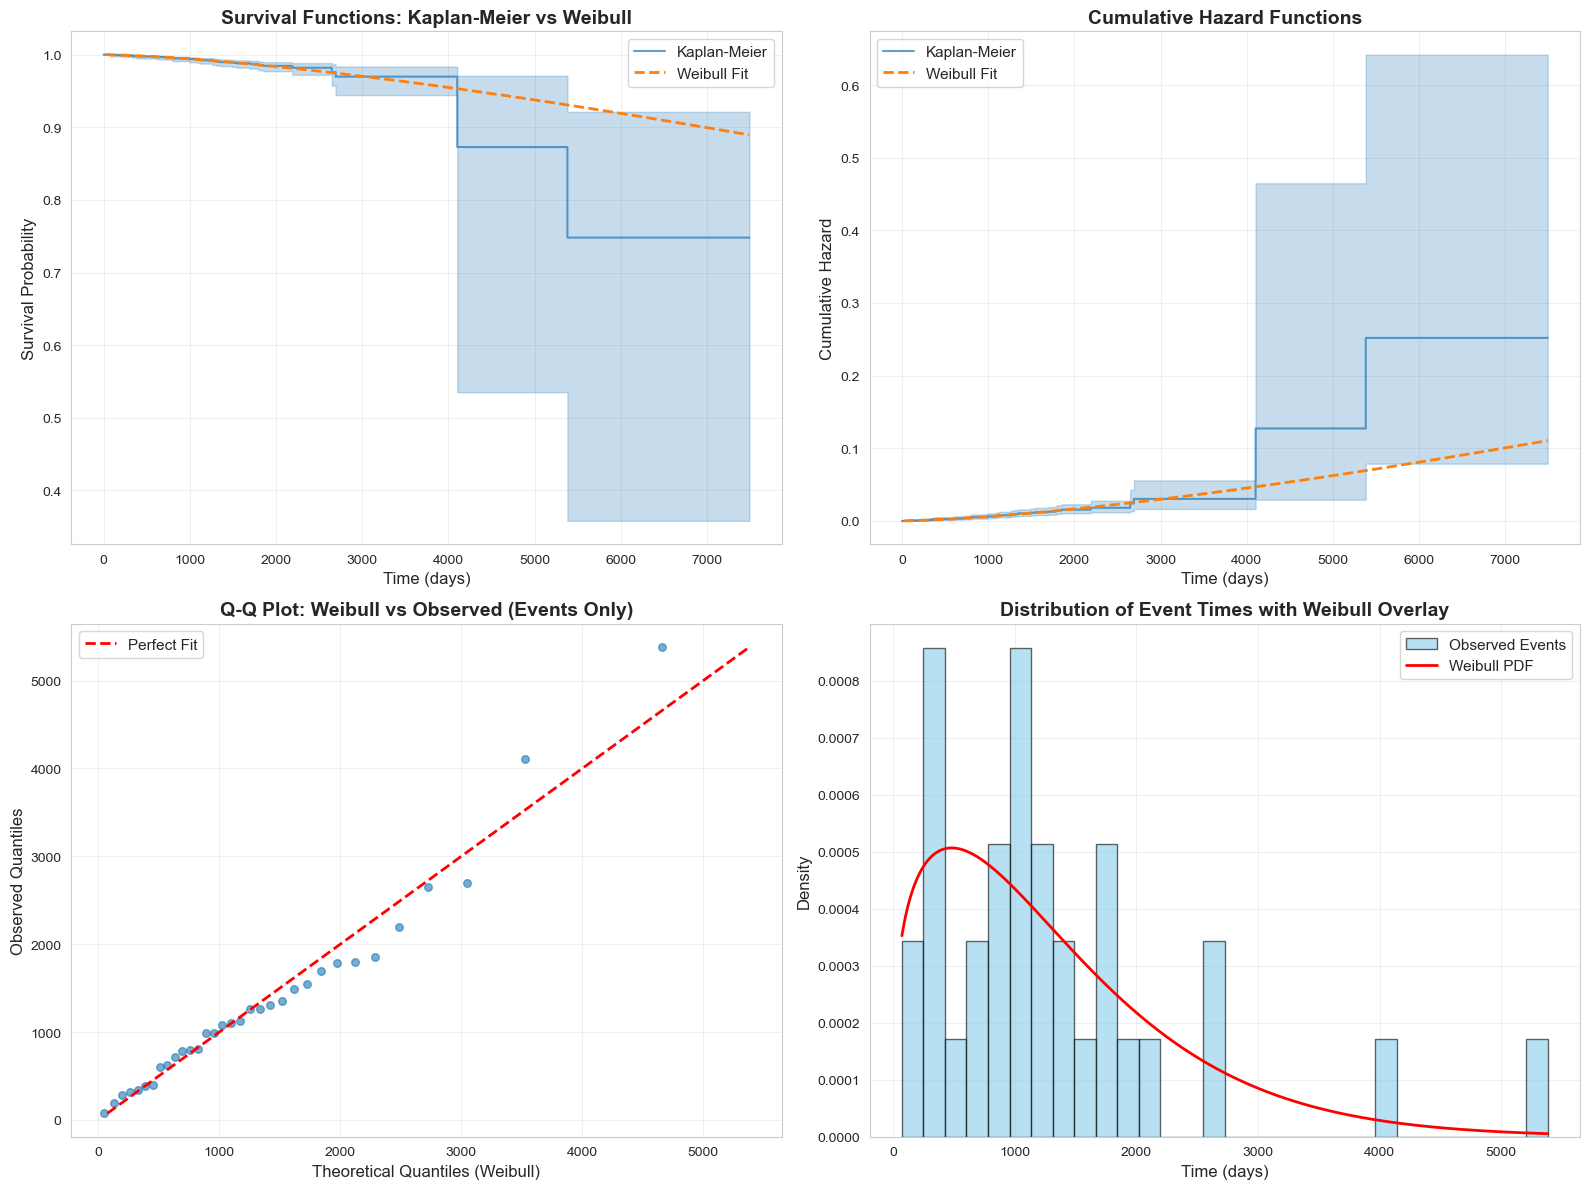

Visual assessment completed. Check if:
  - Weibull curve closely follows Kaplan-Meier
  - Q-Q plot points lie near the diagonal line
  - Histogram matches Weibull PDF shape


In [4]:
# 2. Visual Assessment: Plot Weibull vs Kaplan-Meier
print("\n=== VISUAL COMPARISON ===")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Survival Functions
ax1 = axes[0, 0]
km_fitter.plot_survival_function(ax=ax1, ci_show=True, alpha=0.7)
weibull_fitter.plot_survival_function(ax=ax1, ci_show=False, linestyle='--', linewidth=2)
ax1.set_title('Survival Functions: Kaplan-Meier vs Weibull', fontsize=14, fontweight='bold')
ax1.set_xlabel('Time (days)', fontsize=12)
ax1.set_ylabel('Survival Probability', fontsize=12)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Cumulative Hazard Functions
ax2 = axes[0, 1]
km_fitter.plot_cumulative_density(ax=ax2, ci_show=True, alpha=0.7)
weibull_fitter.plot_cumulative_density(ax=ax2, ci_show=False, linestyle='--', linewidth=2)
ax2.set_title('Cumulative Hazard Functions', fontsize=14, fontweight='bold')
ax2.set_xlabel('Time (days)', fontsize=12)
ax2.set_ylabel('Cumulative Hazard', fontsize=12)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

# Plot 3: Q-Q Plot for events only (uncensored observations)
ax3 = axes[1, 0]
event_times = survival_times[events == 1]

# Fit Weibull to scipy format for event times only
weibull_scipy = weibull_min.fit(event_times, floc=0)
theoretical_quantiles = weibull_min.ppf(np.linspace(0.01, 0.99, len(event_times)), *weibull_scipy)
observed_quantiles = np.sort(event_times)

ax3.scatter(theoretical_quantiles, observed_quantiles, alpha=0.6, s=30)
ax3.plot([observed_quantiles.min(), observed_quantiles.max()], 
         [observed_quantiles.min(), observed_quantiles.max()], 
         'r--', linewidth=2, label='Perfect Fit')
ax3.set_title('Q-Q Plot: Weibull vs Observed (Events Only)', fontsize=14, fontweight='bold')
ax3.set_xlabel('Theoretical Quantiles (Weibull)', fontsize=12)
ax3.set_ylabel('Observed Quantiles', fontsize=12)
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)

# Plot 4: Histogram with Weibull PDF overlay (events only)
ax4 = axes[1, 1]
ax4.hist(event_times, bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Observed Events')

# Generate Weibull PDF
x_range = np.linspace(event_times.min(), event_times.max(), 1000)
weibull_pdf = weibull_min.pdf(x_range, *weibull_scipy)
ax4.plot(x_range, weibull_pdf, 'r-', linewidth=2, label='Weibull PDF')

ax4.set_title('Distribution of Event Times with Weibull Overlay', fontsize=14, fontweight='bold')
ax4.set_xlabel('Time (days)', fontsize=12)
ax4.set_ylabel('Density', fontsize=12)
ax4.legend(fontsize=11)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Visual assessment completed. Check if:")
print("  - Weibull curve closely follows Kaplan-Meier")
print("  - Q-Q plot points lie near the diagonal line")
print("  - Histogram matches Weibull PDF shape")

In [5]:
# 3. Statistical Tests for Goodness-of-Fit
print("\n=== STATISTICAL GOODNESS-OF-FIT TESTS ===\n")

# Use event times only for statistical tests
event_times = survival_times[events == 1]

# Fit Weibull parameters using scipy
weibull_params = weibull_min.fit(event_times, floc=0)
print(f"Scipy Weibull parameters (shape, loc, scale): {weibull_params}")

# 3.1 Kolmogorov-Smirnov Test
ks_statistic, ks_pvalue = stats.kstest(event_times, lambda x: weibull_min.cdf(x, *weibull_params))
print(f"\n1. KOLMOGOROV-SMIRNOV TEST:")
print(f"   Test statistic: {ks_statistic:.4f}")
print(f"   P-value: {ks_pvalue:.4f}")
if ks_pvalue > 0.05:
    print(f"   ✅ RESULT: FAIL TO REJECT null hypothesis (p > 0.05)")
    print(f"   → Data is consistent with Weibull distribution")
else:
    print(f"   ❌ RESULT: REJECT null hypothesis (p ≤ 0.05)")
    print(f"   → Data significantly differs from Weibull distribution")

# 3.2 Anderson-Darling Test (more sensitive to tails)
try:
    # Transform to standard distribution for AD test
    transformed = weibull_min.cdf(event_times, *weibull_params)
    ad_result = stats.anderson(transformed, dist='uniform')
    print(f"\n2. ANDERSON-DARLING TEST (for uniformly transformed data):")
    print(f"   Test statistic: {ad_result.statistic:.4f}")
    print(f"   Critical values: {ad_result.critical_values}")
    print(f"   Significance levels: {ad_result.significance_level}%")
    
    # Check at 5% significance level
    idx_5pct = list(ad_result.significance_level).index(5.0) if 5.0 in ad_result.significance_level else 2
    if ad_result.statistic < ad_result.critical_values[idx_5pct]:
        print(f"   ✅ RESULT: Data is consistent with Weibull at 5% level")
    else:
        print(f"   ❌ RESULT: Data differs from Weibull at 5% level")
except Exception as e:
    print(f"\n2. ANDERSON-DARLING TEST: Could not complete ({str(e)})")

# 3.3 Chi-Square Goodness-of-Fit Test
print(f"\n3. CHI-SQUARE GOODNESS-OF-FIT TEST:")

# Create bins
n_bins = min(10, len(event_times) // 10)  # At least 10 observations per bin
bins = np.percentile(event_times, np.linspace(0, 100, n_bins + 1))
observed_freq, _ = np.histogram(event_times, bins=bins)

# Expected frequencies under Weibull
expected_freq = []
for i in range(len(bins) - 1):
    prob = weibull_min.cdf(bins[i+1], *weibull_params) - weibull_min.cdf(bins[i], *weibull_params)
    expected_freq.append(prob * len(event_times))
expected_freq = np.array(expected_freq)

# Remove bins with expected frequency < 5
valid_bins = expected_freq >= 5
observed_freq = observed_freq[valid_bins]
expected_freq = expected_freq[valid_bins]

chi2_statistic = np.sum((observed_freq - expected_freq)**2 / expected_freq)
df = len(observed_freq) - 1 - 2  # bins - 1 - number of estimated parameters
chi2_pvalue = 1 - stats.chi2.cdf(chi2_statistic, df)

print(f"   Number of bins used: {len(observed_freq)}")
print(f"   Chi-square statistic: {chi2_statistic:.4f}")
print(f"   Degrees of freedom: {df}")
print(f"   P-value: {chi2_pvalue:.4f}")

if chi2_pvalue > 0.05:
    print(f"   ✅ RESULT: FAIL TO REJECT null hypothesis (p > 0.05)")
    print(f"   → Data is consistent with Weibull distribution")
else:
    print(f"   ❌ RESULT: REJECT null hypothesis (p ≤ 0.05)")
    print(f"   → Data significantly differs from Weibull distribution")


=== STATISTICAL GOODNESS-OF-FIT TESTS ===

Scipy Weibull parameters (shape, loc, scale): (np.float64(1.310516716543085), 0, np.float64(1451.6562583493562))

1. KOLMOGOROV-SMIRNOV TEST:
   Test statistic: 0.1003
   P-value: 0.8612
   ✅ RESULT: FAIL TO REJECT null hypothesis (p > 0.05)
   → Data is consistent with Weibull distribution

2. ANDERSON-DARLING TEST: Could not complete (Invalid distribution; dist must be in {'expon', 'gumbel_r', 'gumbel_l', 'logistic', 'weibull_min', 'norm'}.)

3. CHI-SQUARE GOODNESS-OF-FIT TEST:
   Number of bins used: 3
   Chi-square statistic: 1.1895
   Degrees of freedom: 0
   P-value: nan
   ❌ RESULT: REJECT null hypothesis (p ≤ 0.05)
   → Data significantly differs from Weibull distribution


In [6]:
# 4. Model Comparison: AIC and BIC
print("\n=== MODEL COMPARISON (AIC/BIC) ===\n")

# Get AIC and BIC from Weibull fit
weibull_aic = weibull_fitter.AIC_
weibull_bic = weibull_fitter.BIC_

print(f"Weibull Model:")
print(f"  AIC: {weibull_aic:.2f}")
print(f"  BIC: {weibull_bic:.2f}")

# Fit exponential for comparison (special case of Weibull with shape=1)
from lifelines import ExponentialFitter
exp_fitter = ExponentialFitter()
exp_fitter.fit(survival_times, events)

exp_aic = exp_fitter.AIC_
exp_bic = exp_fitter.BIC_

print(f"\nExponential Model (for comparison):")
print(f"  AIC: {exp_aic:.2f}")
print(f"  BIC: {exp_bic:.2f}")

print(f"\nModel Comparison:")
print(f"  ΔAIC (Weibull - Exponential): {weibull_aic - exp_aic:.2f}")
print(f"  ΔBIC (Weibull - Exponential): {weibull_bic - exp_bic:.2f}")

if weibull_aic < exp_aic:
    print(f"  ✅ Weibull has LOWER AIC (better fit)")
else:
    print(f"  ⚠️  Exponential has LOWER AIC")

if weibull_bic < exp_bic:
    print(f"  ✅ Weibull has LOWER BIC (better fit with penalty for complexity)")
else:
    print(f"  ⚠️  Exponential has LOWER BIC")

print(f"\nInterpretation:")
print(f"  Lower AIC/BIC indicates better model fit")
print(f"  BIC penalizes model complexity more than AIC")


=== MODEL COMPARISON (AIC/BIC) ===

Weibull Model:
  AIC: 839.70
  BIC: 851.69

Exponential Model (for comparison):
  AIC: 844.04
  BIC: 850.03

Model Comparison:
  ΔAIC (Weibull - Exponential): -4.34
  ΔBIC (Weibull - Exponential): 1.66
  ✅ Weibull has LOWER AIC (better fit)
  ⚠️  Exponential has LOWER BIC

Interpretation:
  Lower AIC/BIC indicates better model fit
  BIC penalizes model complexity more than AIC



=== COX-SNELL RESIDUALS ===



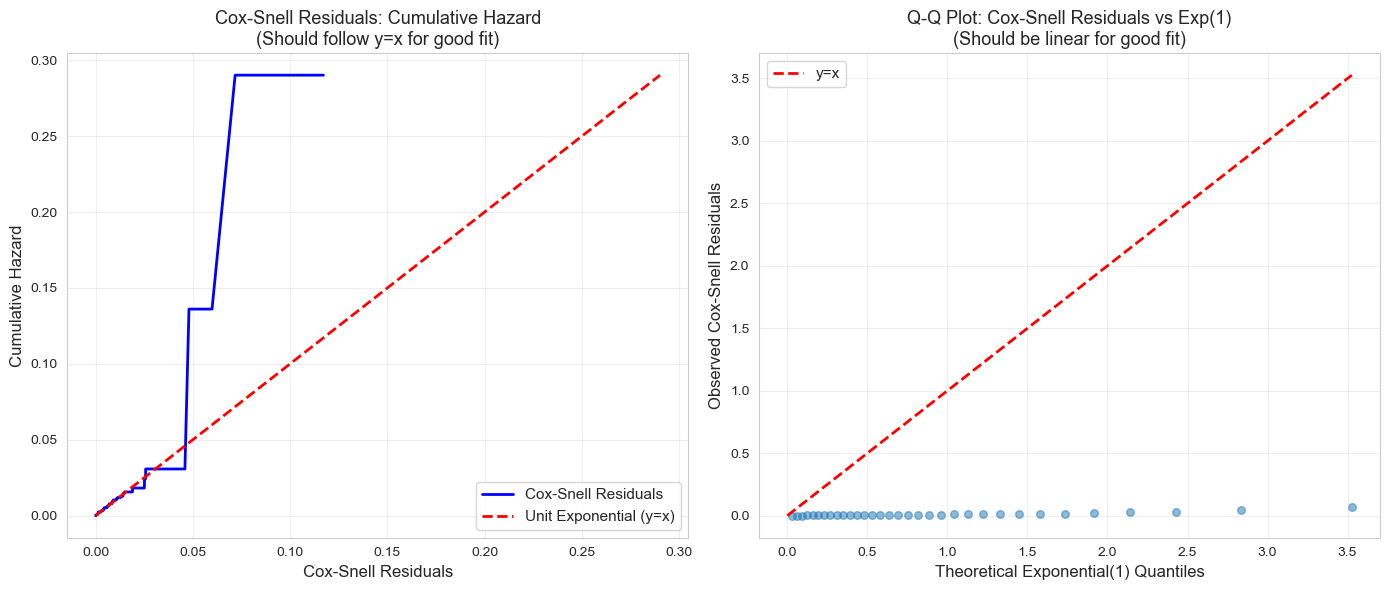

Number of events (uncensored): 33.0
Number of censored: 2937.0

Interpretation:
  • If plots show linear relationship → Good Weibull fit
  • Deviations from linearity → Poor Weibull fit
  • Cox-Snell residuals should follow Exp(1) distribution


In [7]:
# 5. Cox-Snell Residuals for GoF Assessment
print("\n=== COX-SNELL RESIDUALS ===\n")

# Calculate Cox-Snell residuals
# For Weibull: r_i = (t_i / λ)^ρ
lambda_param = weibull_fitter.lambda_
rho_param = weibull_fitter.rho_

cox_snell_residuals = (survival_times / lambda_param) ** rho_param

# Fit KM to Cox-Snell residuals
km_residuals = KaplanMeierFitter()
km_residuals.fit(cox_snell_residuals, event_observed=events)

# For a good fit, Cox-Snell residuals should follow Exp(1)
# So the cumulative hazard should follow a 45-degree line
cumulative_hazard_residuals = -np.log(km_residuals.survival_function_)

# Plot Cox-Snell residuals
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Cumulative Hazard of Cox-Snell Residuals vs Unit Exponential
ax1 = axes[0]
ax1.plot(cumulative_hazard_residuals.index, 
         cumulative_hazard_residuals.values, 
         'b-', linewidth=2, label='Cox-Snell Residuals')
# 45-degree reference line
max_val = cumulative_hazard_residuals.values.max()
ax1.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Unit Exponential (y=x)')
ax1.set_xlabel('Cox-Snell Residuals', fontsize=12)
ax1.set_ylabel('Cumulative Hazard', fontsize=12)
ax1.set_title('Cox-Snell Residuals: Cumulative Hazard\n(Should follow y=x for good fit)', fontsize=13)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Q-Q plot for Cox-Snell residuals vs Exponential(1)
ax2 = axes[1]
from scipy import stats
# For exponential distribution, theoretical quantiles are -log(1-p)
sorted_residuals = np.sort(cox_snell_residuals[events == 1])  # Only use uncensored
n = len(sorted_residuals)
theoretical_quantiles = -np.log(1 - np.arange(1, n + 1) / (n + 1))

ax2.scatter(theoretical_quantiles, sorted_residuals, alpha=0.5, s=30)
# 45-degree reference line
max_q = max(theoretical_quantiles.max(), sorted_residuals.max())
ax2.plot([0, max_q], [0, max_q], 'r--', linewidth=2, label='y=x')
ax2.set_xlabel('Theoretical Exponential(1) Quantiles', fontsize=12)
ax2.set_ylabel('Observed Cox-Snell Residuals', fontsize=12)
ax2.set_title('Q-Q Plot: Cox-Snell Residuals vs Exp(1)\n(Should be linear for good fit)', fontsize=13)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Number of events (uncensored): {events.sum()}")
print(f"Number of censored: {(1-events).sum()}")
print(f"\nInterpretation:")
print(f"  • If plots show linear relationship → Good Weibull fit")
print(f"  • Deviations from linearity → Poor Weibull fit")
print(f"  • Cox-Snell residuals should follow Exp(1) distribution")

## 📊 Summary: Does the Data Follow a Weibull Distribution?

### Decision Criteria:

**✅ Evidence FOR Weibull Distribution:**
- **Visual Checks:**
  - Survival curves closely match
  - Q-Q plot shows linear relationship
  - Histogram overlay fits well
  - Cox-Snell residuals follow y=x line

- **Statistical Tests:**
  - KS test p-value > 0.05 (fail to reject H₀)
  - AD test statistic is low
  - Chi-Square test p-value > 0.05

- **Model Comparison:**
  - Lower AIC/BIC compared to simpler models
  - Shape parameter ρ significantly different from 1

**❌ Evidence AGAINST Weibull Distribution:**
- Large deviations in visual plots
- KS/AD/Chi-Square tests reject null hypothesis (p < 0.05)
- Cox-Snell residuals deviate from y=x
- Higher AIC/BIC than competing models

### Interpretation Guidelines:
- **p-value > 0.05**: Data is consistent with Weibull (cannot reject)
- **p-value < 0.05**: Data significantly deviates from Weibull
- **Multiple tests**: Look for consensus across tests
- **Visual + Statistical**: Both should agree for strong conclusion

### Next Steps:
If Weibull is **accepted**: Can use parametric Weibull regression models
If Weibull is **rejected**: Consider alternative distributions (Log-logistic, Log-normal) or non-parametric models (Cox PH)